In [35]:
import numpy as np
import pandas as pd 
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))
import kagglehub

/kaggle/input/competitions/cyprus-cars-price-oracle/sample_submission.csv
/kaggle/input/competitions/cyprus-cars-price-oracle/train.csv
/kaggle/input/competitions/cyprus-cars-price-oracle/test.csv


In [36]:
train_ds= pd.read_csv("/kaggle/input/competitions/cyprus-cars-price-oracle/train.csv")
test_ds =pd.read_csv("/kaggle/input/competitions/cyprus-cars-price-oracle/test.csv")
sample_sub =pd.read_csv("/kaggle/input/competitions/cyprus-cars-price-oracle/sample_submission.csv")

In [37]:
train_ds.isnull().sum()
#drop power
train_ds = train_ds.drop("Power",axis =1)
test_ds =test_ds.drop("Power",axis =1)

In [38]:
def fix_feats(train_ds, test_ds):
    train_ds = train_ds.copy()
    test_ds = test_ds.copy()
    train_ds["title"] = train_ds["title"].apply(lambda x: x.split()[0])
    test_ds["title"] = test_ds["title"].apply(lambda x: x.split()[0])
    train_ds["Doors"] = train_ds["Doors"].map({"4 - 5 doors": "normal", "2 - 3 doors": "low", "6 doors": "high"})
    test_ds["Doors"] = test_ds["Doors"].map({"4 - 5 doors": "normal", "2 - 3 doors": "low", "6 doors": "high"})
    train_ds["Doors"] = train_ds["Doors"].fillna("Unknown")
    test_ds["Doors"] = test_ds["Doors"].fillna("Unknown")
    for col, threshold in [("Colour", 10), ("Body type", 20), ("location", 10)]:
        cnts = train_ds[col].value_counts()
        valid = cnts[cnts >= threshold].index
        train_ds[col] = train_ds[col].where(train_ds[col].isin(valid), "Other")
        test_ds[col] = test_ds[col].where(test_ds[col].isin(valid), "Other")
    def convert_engine(x):
        if pd.isna(x):
            return np.nan
        x = str(x)
        if x == "Electric":
            return np.nan
        if "cc" in x:
            x = x.replace(" cc", "")
            if "+" in x:
                return float(x.replace("+", "")) / 1000
            nums = [float(n) for n in x.split("-")]
            return sum(nums) / 2000
        return float(x.replace("L", "").replace(",", "."))
    train_ds["Engine size"] = train_ds["Engine size"].apply(convert_engine).fillna(-1)
    test_ds["Engine size"] = test_ds["Engine size"].apply(convert_engine).fillna(-1)
    train_ds["Seats"] =train_ds["Seats"].apply(lambda x:float(x))
    test_ds["Seats"] = test_ds["Seats"].apply(lambda x:float(x))
    return train_ds, test_ds
train_ds, test_ds = fix_feats(train_ds, test_ds)

In [39]:
num_cols= ["Year","Engine size","Seats"]

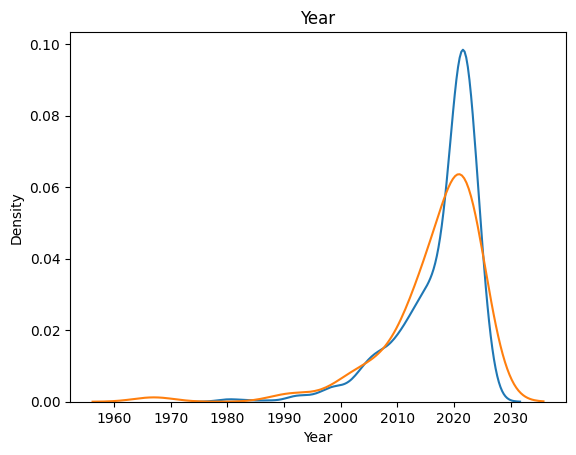

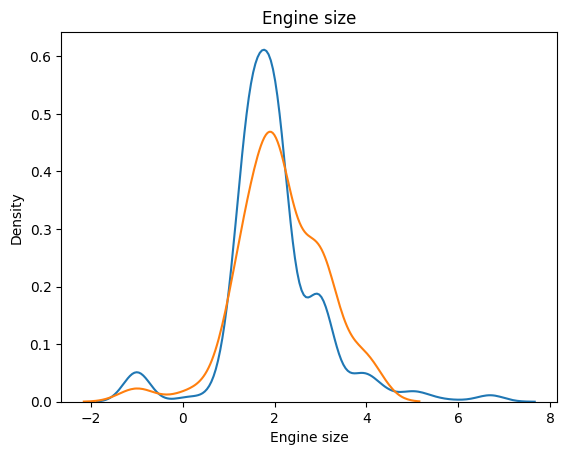

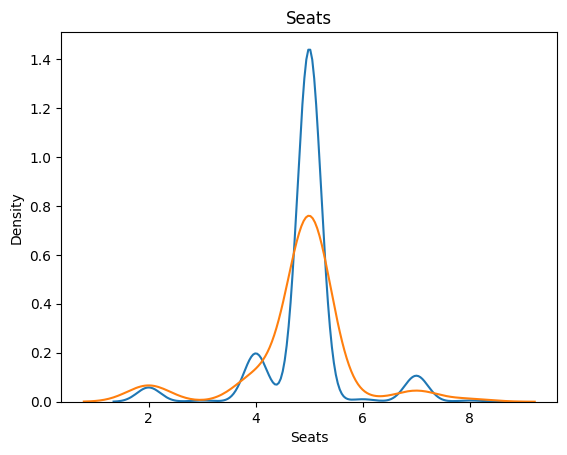

In [40]:
import seaborn as sns
import matplotlib.pyplot as plt
for col in num_cols:
    sns.kdeplot(train_ds[col])
    sns.kdeplot(test_ds[col])
    plt.title(col);plt.show()

In [41]:
from sklearn.impute import SimpleImputer
cat_null_cols = ["Drive","Seats","Colour","Gearbox","Body type","Fuel type"]
imputer=  SimpleImputer(strategy = "most_frequent").fit(train_ds[cat_null_cols])
train_ds[cat_null_cols]=imputer.transform(train_ds[cat_null_cols])
test_ds[cat_null_cols]=imputer.transform(test_ds[cat_null_cols])

In [42]:
from sklearn.preprocessing import MultiLabelBinarizer
extras = train_ds["Extras"].fillna("").apply(
    lambda x: [item.strip() for item in x.split(",") if item.strip()]
)
mlb = MultiLabelBinarizer()
extras_encoded = pd.DataFrame(
    mlb.fit_transform(extras),
    columns=["Extra_" + c for c in mlb.classes_],
    index=train_ds.index
)
train_ds = pd.concat([train_ds.drop(columns=["Extras"]), extras_encoded], axis=1)
extras = test_ds["Extras"].fillna("").apply(
    lambda x: [item.strip() for item in x.split(",") if item.strip()]
)
extras_encoded = pd.DataFrame(
    mlb.transform(extras),
    columns=["Extra_" + c for c in mlb.classes_],
    index=test_ds.index
)
test_ds = pd.concat([test_ds.drop(columns=["Extras"]), extras_encoded], axis=1)

In [43]:
cat_cols= [col for col in train_ds.select_dtypes(include=["object","category"]).columns if col!="MOT till"]

In [44]:
from sklearn.preprocessing import OrdinalEncoder
encoder= OrdinalEncoder(handle_unknown ="use_encoded_value", unknown_value=-1).fit(train_ds[cat_cols])
train_ds[cat_cols]=encoder.transform(train_ds[cat_cols])
test_ds[cat_cols]=encoder.transform(test_ds[cat_cols])
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler().fit(train_ds[num_cols])
train_ds[num_cols]=scaler.transform(train_ds[num_cols])
test_ds[num_cols] = scaler.transform(test_ds[num_cols])

In [45]:
X_cols = [col for col in train_ds.columns if col not in ["price","MOT till"]]

In [46]:
train_ds['Mileage (in km)'] = train_ds['Mileage (in km)'].fillna(train_ds['Mileage (in km)'].mean())
test_ds['Mileage (in km)'] = test_ds['Mileage (in km)'].fillna(test_ds['Mileage (in km)'].mean())
train_ds["price"] =np.log1p(train_ds["price"])

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor
from catboost import CatBoostRegressor
from sklearn.model_selection import RandomizedSearchCV

cat = CatBoostRegressor(task_type="GPU", verbose=0)

cat_params = {
    "iterations": [500, 1000, 1500],
    "bootstrap_type": ["Bernoulli"],
    "learning_rate": [0.001, 0.01, 0.1, 0.05, 0.5],
    "loss_function": ["RMSE"],
    "l2_leaf_reg": [0.8, 1, 2, 3, 4],
    "depth": [4, 6, 7, 8],
    "subsample": [0.5, 0.7, 0.8, 1],
    "random_strength": [1, 2]
}

cat = RandomizedSearchCV(
    cat,
    cat_params,
    n_iter=30,
    cv=5,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=1,
    verbose=1
).fit(train_ds[X_cols], train_ds["price"])

print(cat.best_params_)
print(-cat.best_score_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


In [ ]:
sample_sub["price"]=cat.predict(test_ds[X_cols])
sample_sub["price"] =np.expm1(sample_sub["price"])
sample_sub.to_csv("grad1.csv",index= False)